# Benchmark Data Analysis

## Project Overview

This notebook analyzes benchmark latency measurements for two monitoring conditions:

- output_only
- cot_plus_output

## Objectives

- Calculate descriptive statistics.
- Estimate 95% Bootstrap Confidence Intervals.
- Identify outliers using the IQR method.
- Visualize latency distributions.

In [13]:
import json
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Data Loading

In this section, we load the raw benchmark measurements from the JSONL file and inspect the dataset structure.

In [25]:
# Define the input data path
DATA_PATH = Path("../data/raw/test_run_load.jsonl")

# Load JSONL records
records = []

with DATA_PATH.open("r", encoding="utf-8") as file:
    for line in file:
        if line.strip():
            records.append(json.loads(line))

# Convert records to DataFrame
df = pd.DataFrame(records)

print("Dataset loaded successfully!")
print("Total records:", len(df))

display(df.head())

Dataset loaded successfully!
Total records: 420


,timestamp,phase,repeat,request_index,episode_id,category,label,condition,backend,request_rate_rps,status,score,latency_ms,error_type,error_message,run_started,achieved_rps,batch_elapsed_seconds
0,2026-11-03T09:32:04.662168+00:00,warmup,1,NaN,s01,safe,safe,output_only,keyword,NaN,success,0,0.6709,None,None,2026-11-03T09:32:04.661376+00:00,NaN,NaN
1,2026-11-03T09:32:04.662921+00:00,warmup,1,NaN,s01,safe,safe,cot_plus_output,keyword,NaN,success,0,0.0543,None,None,2026-11-03T09:32:04.661376+00:00,NaN,NaN
2,2026-11-03T09:32:04.663016+00:00,warmup,1,NaN,s02,safe,safe,output_only,keyword,NaN,success,0,0.0455,None,None,2026-11-03T09:32:04.661376+00:00,NaN,NaN
3,2026-11-03T09:32:04.663087+00:00,warmup,1,NaN,s02,safe,safe,cot_plus_output,keyword,NaN,success,0,0.0565,None,None,2026-11-03T09:32:04.661376+00:00,NaN,NaN
4,2026-11-03T09:32:04.663163+00:00,warmup,1,NaN,s03,safe,safe,output_only,keyword,NaN,success,0,0.0350,None,None,2026-11-03T09:32:04.661376+00:00,NaN,NaN


## 2. Data Filtering

Warmup measurements are excluded from the statistical analysis.
Only successful benchmark measurements are retained for latency calculations.
Failed measurements are counted separately as a quality-control indicator.

In [26]:
# Separate warmup and benchmark records
warmup_df = df[df["phase"] == "warmup"].copy()

benchmark_df = df[df["phase"] == "benchmark"].copy()

# Separate successful and failed measurements
successful_df = benchmark_df[
    benchmark_df["status"] == "success"
].copy()

failed_df = benchmark_df[
    benchmark_df["status"] != "success"
].copy()

# Keep valid latency measurements
successful_df["latency_ms"] = pd.to_numeric(
    successful_df["latency_ms"],
    errors="coerce"
)

valid_latency_df = successful_df[
    successful_df["latency_ms"].notna()
    & (successful_df["latency_ms"] >= 0)
].copy()

# Display validation results
print("Warmup records excluded:", len(warmup_df))
print("Benchmark records:", len(benchmark_df))
print("Successful measurements:", len(successful_df))
print("Failed measurements:", len(failed_df))
print("Valid latency measurements:", len(valid_latency_df))

print("\nRequest rates:")
print(sorted(valid_latency_df["request_rate_rps"].unique()))

print("\nConditions:")
print(valid_latency_df["condition"].unique())

Warmup records excluded: 20
Benchmark records: 400
Successful measurements: 400
Failed measurements: 0
Valid latency measurements: 400

Request rates:
[np.float64(1.0), np.float64(5.0), np.float64(10.0), np.float64(20.0)]

Conditions:
<StringArray>
['output_only', 'cot_plus_output']
Length: 2, dtype: str


## 3. Descriptive Statistics

Descriptive statistics are calculated separately for each monitoring condition.

The analysis includes:
- Mean latency
- Standard deviation
- Median
- 95th percentile (P95)
- 99th percentile (P99)
- Minimum and maximum latency

In [27]:
# Calculate descriptive statistics by request rate and condition

grouped = valid_latency_df.groupby(
    ["request_rate_rps", "condition"]
)["latency_ms"]

descriptive_stats = grouped.agg(
    count="count",
    mean="mean",
    std="std",
    median="median",
    minimum="min",
    maximum="max"
).reset_index()

# Calculate P95 and P99
percentiles = grouped.quantile([0.95, 0.99]).unstack()

percentiles = percentiles.rename(columns={
    0.95: "p95",
    0.99: "p99"
}).reset_index()

descriptive_stats = descriptive_stats.merge(
    percentiles,
    on=["request_rate_rps", "condition"]
)

display(descriptive_stats.round(4))

,request_rate_rps,condition,count,mean,std,median,minimum,maximum,p95,p99
0,1.0,cot_plus_output,50,0.2114,0.0589,0.1984,0.1125,0.4741,0.3077,0.3950
1,1.0,output_only,50,0.2158,0.1032,0.2047,0.1207,0.8650,0.2829,0.5860
2,5.0,cot_plus_output,50,0.2298,0.0956,0.2028,0.1105,0.7557,0.3304,0.5843
3,5.0,output_only,50,0.2023,0.0507,0.1914,0.0791,0.3329,0.3021,0.3276
4,10.0,cot_plus_output,50,0.2182,0.0385,0.2204,0.1363,0.3091,0.2846,0.3029
5,10.0,output_only,50,0.2099,0.0482,0.2023,0.1131,0.3434,0.3082,0.3395
6,20.0,cot_plus_output,50,0.2139,0.0723,0.2156,0.1284,0.5462,0.2978,0.4379
7,20.0,output_only,50,0.1943,0.0532,0.1913,0.1153,0.3799,0.2758,0.3298


## 4. Bootstrap Confidence Intervals

A percentile bootstrap procedure is used to estimate 95% confidence intervals for mean latency.

For each monitoring condition, observations are resampled with replacement. The 2.5th and 97.5th percentiles of bootstrap means define the confidence interval.

The random seed is fixed to ensure reproducibility.

In [17]:
import yaml

# Load experiment settings
CONFIG_PATH = Path("../configs/config.yaml")

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

BOOTSTRAP_RESAMPLES = int(
    config["statistics"]["bootstrap_resamples"]
)

RANDOM_SEED = int(config["experiment"]["seed"])

print("Bootstrap resamples:", BOOTSTRAP_RESAMPLES)
print("Random seed:", RANDOM_SEED)

Bootstrap resamples: 2000
Random seed: 42


In [18]:
def bootstrap_mean_ci(values, n_resamples=2000, seed=42):
    values = np.asarray(values, dtype=float)

    rng = np.random.default_rng(seed)

    bootstrap_means = np.empty(n_resamples)

    for i in range(n_resamples):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )
        bootstrap_means[i] = np.mean(sample)

    lower, upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    return float(lower), float(upper)


bootstrap_results = []

conditions = sorted(successful_df["condition"].unique())

for index, condition in enumerate(conditions):

    values = successful_df.loc[
        successful_df["condition"] == condition,
        "latency_ms"
    ].to_numpy()

    lower, upper = bootstrap_mean_ci(
        values,
        n_resamples=BOOTSTRAP_RESAMPLES,
        seed=RANDOM_SEED + index
    )

    bootstrap_results.append({
        "condition": condition,
        "bootstrap_ci_lower_ms": lower,
        "bootstrap_ci_upper_ms": upper
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

display(bootstrap_df.round(6))

,condition,bootstrap_ci_lower_ms,bootstrap_ci_upper_ms
0,cot_plus_output,0.039738,0.043756
1,output_only,0.037666,0.042274


In [28]:
# Calculate 95% Bootstrap Confidence Intervals

import yaml

config = yaml.safe_load(
    Path("../configs/config.yaml").read_text(encoding="utf-8")
)

bootstrap_resamples = int(
    config["statistics"]["bootstrap_resamples"]
)

seed = int(config["experiment"]["seed"])

rng = np.random.default_rng(seed)

bootstrap_results = []

for (rps, condition), group in valid_latency_df.groupby(
    ["request_rate_rps", "condition"]
):
    values = group["latency_ms"].to_numpy()

    bootstrap_means = np.empty(bootstrap_resamples)

    for i in range(bootstrap_resamples):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )
        bootstrap_means[i] = np.mean(sample)

    ci_lower, ci_upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    bootstrap_results.append({
        "request_rate_rps": rps,
        "condition": condition,
        "ci_lower_ms": ci_lower,
        "ci_upper_ms": ci_upper
    })

bootstrap_df = pd.DataFrame(bootstrap_results)

display(bootstrap_df.round(4))

,request_rate_rps,condition,ci_lower_ms,ci_upper_ms
0,1.0,cot_plus_output,0.1957,0.2275
1,1.0,output_only,0.1926,0.2495
2,5.0,cot_plus_output,0.2062,0.2586
3,5.0,output_only,0.1891,0.2170
4,10.0,cot_plus_output,0.2074,0.2294
5,10.0,output_only,0.1969,0.2239
6,20.0,cot_plus_output,0.1952,0.2357
7,20.0,output_only,0.1801,0.2090


In [29]:
# Combine descriptive statistics and confidence intervals

summary_df = descriptive_stats.merge(
    bootstrap_df,
    on=["request_rate_rps", "condition"]
)

display(summary_df.round(4))

,request_rate_rps,condition,count,mean,std,median,minimum,maximum,p95,p99,ci_lower_ms,ci_upper_ms
0,1.0,cot_plus_output,50,0.2114,0.0589,0.1984,0.1125,0.4741,0.3077,0.3950,0.1957,0.2275
1,1.0,output_only,50,0.2158,0.1032,0.2047,0.1207,0.8650,0.2829,0.5860,0.1926,0.2495
2,5.0,cot_plus_output,50,0.2298,0.0956,0.2028,0.1105,0.7557,0.3304,0.5843,0.2062,0.2586
3,5.0,output_only,50,0.2023,0.0507,0.1914,0.0791,0.3329,0.3021,0.3276,0.1891,0.2170
4,10.0,cot_plus_output,50,0.2182,0.0385,0.2204,0.1363,0.3091,0.2846,0.3029,0.2074,0.2294
5,10.0,output_only,50,0.2099,0.0482,0.2023,0.1131,0.3434,0.3082,0.3395,0.1969,0.2239
6,20.0,cot_plus_output,50,0.2139,0.0723,0.2156,0.1284,0.5462,0.2978,0.4379,0.1952,0.2357
7,20.0,output_only,50,0.1943,0.0532,0.1913,0.1153,0.3799,0.2758,0.3298,0.1801,0.2090


## 5. Outlier Analysis

Potential outliers are identified using the Interquartile Range (IQR) method.

The lower and upper fences are calculated as:

- Lower fence = Q1 − 1.5 × IQR
- Upper fence = Q3 + 1.5 × IQR

Outliers are flagged but not removed from the dataset. All valid benchmark measurements remain included in the statistical analysis.

In [19]:
outlier_results = []

for condition in conditions:

    values = successful_df.loc[
        successful_df["condition"] == condition,
        "latency_ms"
    ]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outliers = values[
        (values < lower_fence) |
        (values > upper_fence)
    ]

    outlier_results.append({
        "condition": condition,
        "Q1_ms": q1,
        "Q3_ms": q3,
        "IQR_ms": iqr,
        "lower_fence_ms": lower_fence,
        "upper_fence_ms": upper_fence,
        "outlier_count": len(outliers),
        "outlier_percentage": len(outliers) / len(values) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(6))

,condition,Q1_ms,Q3_ms,IQR_ms,lower_fence_ms,upper_fence_ms,outlier_count,outlier_percentage
0,cot_plus_output,0.036875,0.042575,0.005700,0.028325,0.051125,5,10.0
1,output_only,0.034325,0.040500,0.006175,0.025062,0.049763,6,12.0


In [30]:
# Non-destructive outlier detection using IQR

outlier_results = []

for (rps, condition), group in valid_latency_df.groupby(
    ["request_rate_rps", "condition"]
):
    values = group["latency_ms"]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outliers = (
        (values < lower_fence) |
        (values > upper_fence)
    )

    outlier_results.append({
        "request_rate_rps": rps,
        "condition": condition,
        "q1_ms": q1,
        "q3_ms": q3,
        "iqr_ms": iqr,
        "lower_fence_ms": lower_fence,
        "upper_fence_ms": upper_fence,
        "outlier_count": int(outliers.sum()),
        "outlier_percentage": float(outliers.mean() * 100)
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(4))

,request_rate_rps,condition,q1_ms,q3_ms,iqr_ms,lower_fence_ms,upper_fence_ms,outlier_count,outlier_percentage
0,1.0,cot_plus_output,0.1728,0.2306,0.0577,0.0863,0.3172,1,2.0
1,1.0,output_only,0.1690,0.2290,0.0600,0.0789,0.3191,1,2.0
2,5.0,cot_plus_output,0.1736,0.2589,0.0853,0.0456,0.3869,2,4.0
3,5.0,output_only,0.1710,0.2295,0.0584,0.0834,0.3171,3,6.0
4,10.0,cot_plus_output,0.1914,0.2388,0.0474,0.1203,0.3099,0,0.0
5,10.0,output_only,0.1846,0.2376,0.0530,0.1050,0.3171,3,6.0
6,20.0,cot_plus_output,0.1660,0.2525,0.0865,0.0363,0.3823,1,2.0
7,20.0,output_only,0.1580,0.2237,0.0657,0.0596,0.3222,1,2.0


## 6. Combined Statistical Summary

This section combines descriptive statistics, bootstrap confidence intervals, and outlier indicators into one summary table.

In [20]:
summary_df = (
    descriptive_stats
    .merge(bootstrap_df, on="condition")
    .merge(outlier_df, on="condition")
)

summary_df["failed_measurements"] = [
    int(
        (
            (benchmark_df["condition"] == condition) &
            (benchmark_df["status"] != "success")
        ).sum()
    )
    for condition in summary_df["condition"]
]

summary_df["warmup_records_excluded"] = len(warmup_df)

summary_df = summary_df.round(6)

display(summary_df)

,condition,count,mean,std,median,minimum,maximum,p95,p99,bootstrap_ci_lower_ms,bootstrap_ci_upper_ms,Q1_ms,Q3_ms,IQR_ms,lower_fence_ms,upper_fence_ms,outlier_count,outlier_percentage,failed_measurements,warmup_records_excluded
0,cot_plus_output,50,0.041626,0.007396,0.0397,0.0347,0.0638,0.061985,0.063604,0.039738,0.043756,0.036875,0.042575,0.005700,0.028325,0.051125,5,10.0,0,20
1,output_only,50,0.039856,0.008832,0.0372,0.0326,0.0722,0.060940,0.067300,0.037666,0.042274,0.034325,0.040500,0.006175,0.025062,0.049763,6,12.0,0,20


In [31]:
# Combine all statistical results

summary_df = (
    descriptive_stats
    .merge(
        bootstrap_df,
        on=["request_rate_rps", "condition"]
    )
    .merge(
        outlier_df,
        on=["request_rate_rps", "condition"]
    )
)

# Add failed measurement counts
error_summary = (
    benchmark_df
    .groupby(["request_rate_rps", "condition"])
    .agg(failed_measurements=(
        "status",
        lambda x: (x != "success").sum()
    ))
    .reset_index()
)

summary_df = summary_df.merge(
    error_summary,
    on=["request_rate_rps", "condition"],
    how="left"
)

summary_df["failed_measurements"] = (
    summary_df["failed_measurements"].fillna(0).astype(int)
)

display(summary_df.round(4))

,request_rate_rps,condition,count,mean,std,median,minimum,maximum,p95,p99,ci_lower_ms,ci_upper_ms,q1_ms,q3_ms,iqr_ms,lower_fence_ms,upper_fence_ms,outlier_count,outlier_percentage,failed_measurements
0,1.0,cot_plus_output,50,0.2114,0.0589,0.1984,0.1125,0.4741,0.3077,0.3950,0.1957,0.2275,0.1728,0.2306,0.0577,0.0863,0.3172,1,2.0,0
1,1.0,output_only,50,0.2158,0.1032,0.2047,0.1207,0.8650,0.2829,0.5860,0.1926,0.2495,0.1690,0.2290,0.0600,0.0789,0.3191,1,2.0,0
2,5.0,cot_plus_output,50,0.2298,0.0956,0.2028,0.1105,0.7557,0.3304,0.5843,0.2062,0.2586,0.1736,0.2589,0.0853,0.0456,0.3869,2,4.0,0
3,5.0,output_only,50,0.2023,0.0507,0.1914,0.0791,0.3329,0.3021,0.3276,0.1891,0.2170,0.1710,0.2295,0.0584,0.0834,0.3171,3,6.0,0
4,10.0,cot_plus_output,50,0.2182,0.0385,0.2204,0.1363,0.3091,0.2846,0.3029,0.2074,0.2294,0.1914,0.2388,0.0474,0.1203,0.3099,0,0.0,0
5,10.0,output_only,50,0.2099,0.0482,0.2023,0.1131,0.3434,0.3082,0.3395,0.1969,0.2239,0.1846,0.2376,0.0530,0.1050,0.3171,3,6.0,0
6,20.0,cot_plus_output,50,0.2139,0.0723,0.2156,0.1284,0.5462,0.2978,0.4379,0.1952,0.2357,0.1660,0.2525,0.0865,0.0363,0.3823,1,2.0,0
7,20.0,output_only,50,0.1943,0.0532,0.1913,0.1153,0.3799,0.2758,0.3298,0.1801,0.2090,0.1580,0.2237,0.0657,0.0596,0.3222,1,2.0,0


In [35]:
# Calculate achieved throughput for each request rate

throughput_df = (
    benchmark_df
    .groupby("request_rate_rps")
    .agg(
        achieved_throughput_rps=("achieved_rps", "mean")
    )
    .reset_index()
)

summary_df = summary_df.merge(
    throughput_df,
    on="request_rate_rps",
    how="left"
)

display(
    summary_df[
        [
            "request_rate_rps",
            "achieved_throughput_rps",
            "condition",
            "mean",
            "median",
            "p95",
            "p99"
        ]
    ].round(4)
)

,request_rate_rps,achieved_throughput_rps,condition,mean,median,p95,p99
0,1.0,1.0101,cot_plus_output,0.2114,0.1984,0.3077,0.3950
1,1.0,1.0101,output_only,0.2158,0.2047,0.2829,0.5860
2,5.0,5.0503,cot_plus_output,0.2298,0.2028,0.3304,0.5843
3,5.0,5.0503,output_only,0.2023,0.1914,0.3021,0.3276
4,10.0,10.1000,cot_plus_output,0.2182,0.2204,0.2846,0.3029
5,10.0,10.1000,output_only,0.2099,0.2023,0.3082,0.3395
6,20.0,20.1982,cot_plus_output,0.2139,0.2156,0.2978,0.4379
7,20.0,20.1982,output_only,0.1943,0.1913,0.2758,0.3298


## 7. Export Statistical Results

The combined statistical summary is exported as a CSV file for reproducibility and further reporting.

In [21]:
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SUMMARY_PATH = PROCESSED_DIR / "metrics_summary_notebook.csv"

summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)

print("Summary exported successfully!")
print("Saved to:", SUMMARY_PATH)

Summary exported successfully!
Saved to: ..\data\processed\metrics_summary_notebook.csv


In [32]:
# Export final statistical summary

OUTPUT_PATH = Path("../data/processed/metrics_summary.csv")

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Summary exported successfully!")
print("File:", OUTPUT_PATH)
print("Total summary rows:", len(summary_df))

Summary exported successfully!
File: ..\data\processed\metrics_summary.csv
Total summary rows: 8


## 8. Figure 1 — Mean Latency Comparison

The figure compares mean benchmark latency between the two monitoring conditions.

Error bars represent 95% percentile bootstrap confidence intervals.

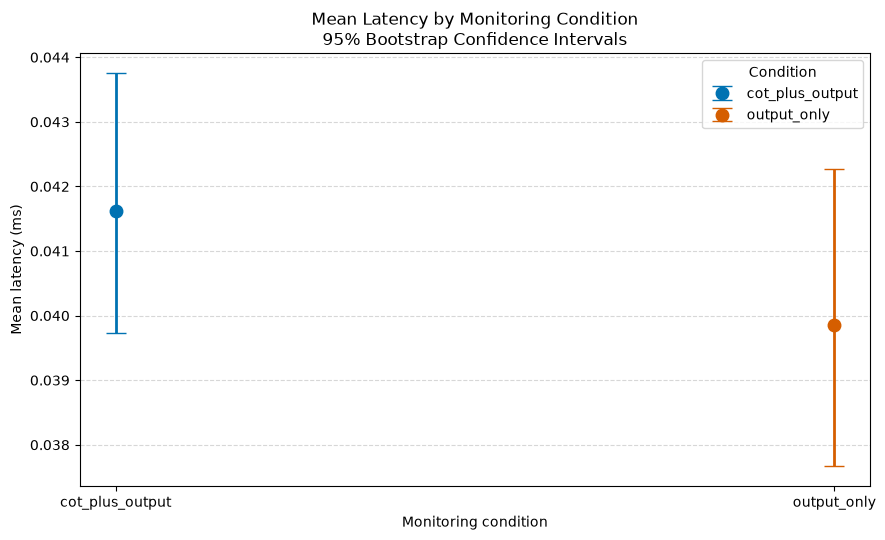

In [22]:
fig, ax = plt.subplots(figsize=(9, 5.5))

colors = ["#0072B2", "#D55E00"]

for index, row in summary_df.reset_index(drop=True).iterrows():

    mean = row["mean"]
    lower = mean - row["bootstrap_ci_lower_ms"]
    upper = row["bootstrap_ci_upper_ms"] - mean

    ax.errorbar(
        index,
        mean,
        yerr=[[lower], [upper]],
        fmt="o",
        markersize=9,
        capsize=7,
        elinewidth=2,
        color=colors[index],
        label=row["condition"]
    )

ax.set_xticks(
    range(len(summary_df)),
    summary_df["condition"]
)

ax.set_xlabel("Monitoring condition")
ax.set_ylabel("Mean latency (ms)")
ax.set_title(
    "Mean Latency by Monitoring Condition\n"
    "95% Bootstrap Confidence Intervals"
)

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(title="Condition")

plt.tight_layout()
FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "fig1_latency_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "fig1_latency_comparison.pdf",
    bbox_inches="tight"
)
plt.show()

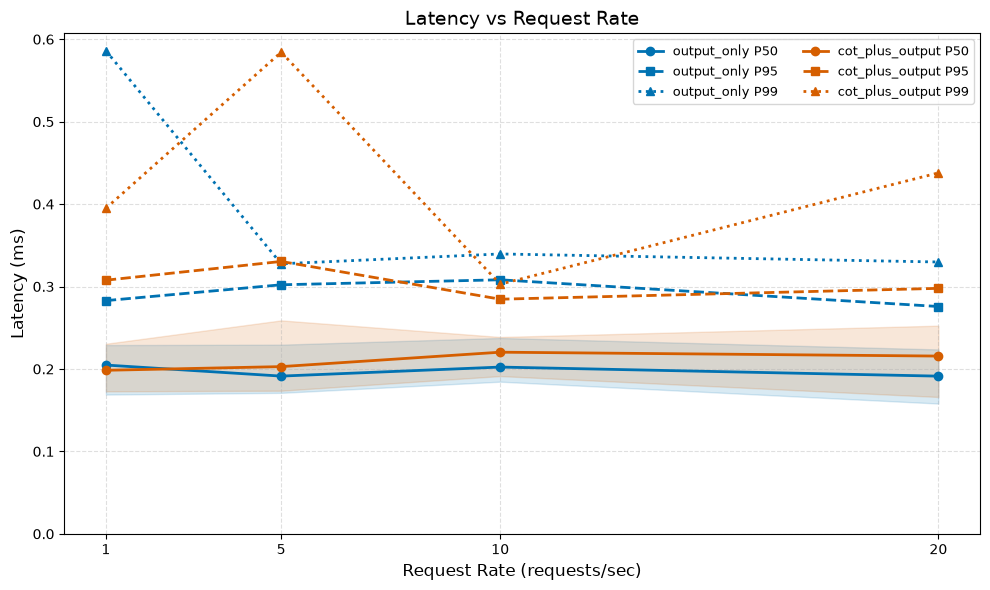

In [33]:
# Plot 1: Latency vs Request Rate

import matplotlib.pyplot as plt

conditions = ["output_only", "cot_plus_output"]

colors = {
    "output_only": "#0072B2",
    "cot_plus_output": "#D55E00"
}

markers = {
    "P50": "o",
    "P95": "s",
    "P99": "^"
}

linestyles = {
    "P50": "-",
    "P95": "--",
    "P99": ":"
}

fig, ax = plt.subplots(figsize=(10, 6))

for condition in conditions:
    data = summary_df[
        summary_df["condition"] == condition
    ].sort_values("request_rate_rps")

    x = data["request_rate_rps"]

    ax.fill_between(
        x,
        data["q1_ms"],
        data["q3_ms"],
        color=colors[condition],
        alpha=0.15
    )

    for metric in ["P50", "P95", "P99"]:
        column = {
            "P50": "median",
            "P95": "p95",
            "P99": "p99"
        }[metric]

        ax.plot(
            x,
            data[column],
            color=colors[condition],
            marker=markers[metric],
            linestyle=linestyles[metric],
            linewidth=2,
            label=f"{condition} {metric}"
        )

ax.set_xlabel("Request Rate (requests/sec)", fontsize=12)
ax.set_ylabel("Latency (ms)", fontsize=12)
ax.set_title("Latency vs Request Rate", fontsize=14)

ax.set_xticks(sorted(summary_df["request_rate_rps"].unique()))
ax.set_ylim(bottom=0)

ax.grid(linestyle="--", alpha=0.4)
ax.legend(fontsize=9, ncol=2)

plt.tight_layout()

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "fig1_latency_vs_load_notebook.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "fig1_latency_vs_load_notebook.pdf",
    bbox_inches="tight"
)

plt.show()

## 9. Figure 2 — Latency Distribution

The boxplot compares benchmark latency distributions across monitoring conditions.

The plot shows medians, interquartile ranges, means, and potential outliers.

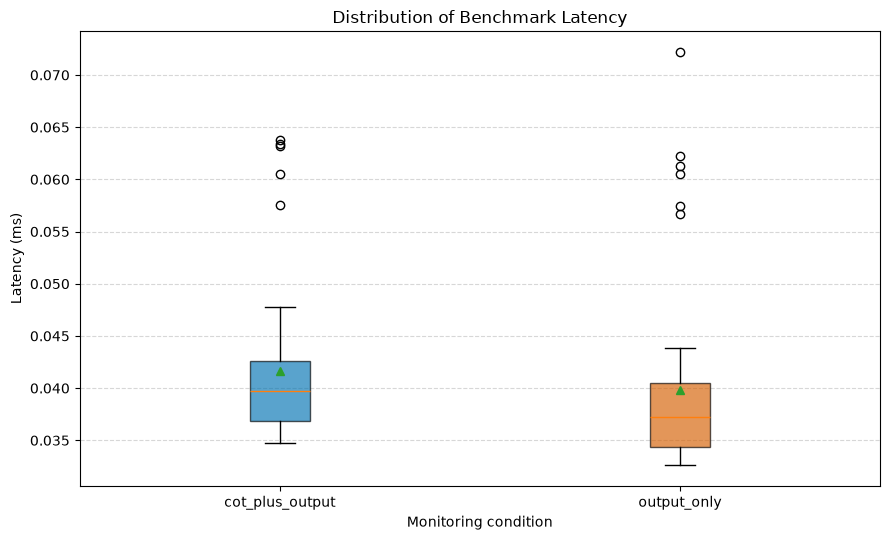

In [23]:
fig, ax = plt.subplots(figsize=(9, 5.5))

box_data = [
    successful_df.loc[
        successful_df["condition"] == condition,
        "latency_ms"
    ].values
    for condition in conditions
]

boxplot = ax.boxplot(
    box_data,
    tick_labels=conditions,
    patch_artist=True,
    showmeans=True,
    showfliers=True
)

colors = ["#0072B2", "#D55E00"]

for patch, color in zip(boxplot["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

ax.set_xlabel("Monitoring condition")
ax.set_ylabel("Latency (ms)")
ax.set_title("Distribution of Benchmark Latency")

ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "fig2_distribution_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "fig2_distribution_boxplot.pdf",
    bbox_inches="tight"
)
plt.show()

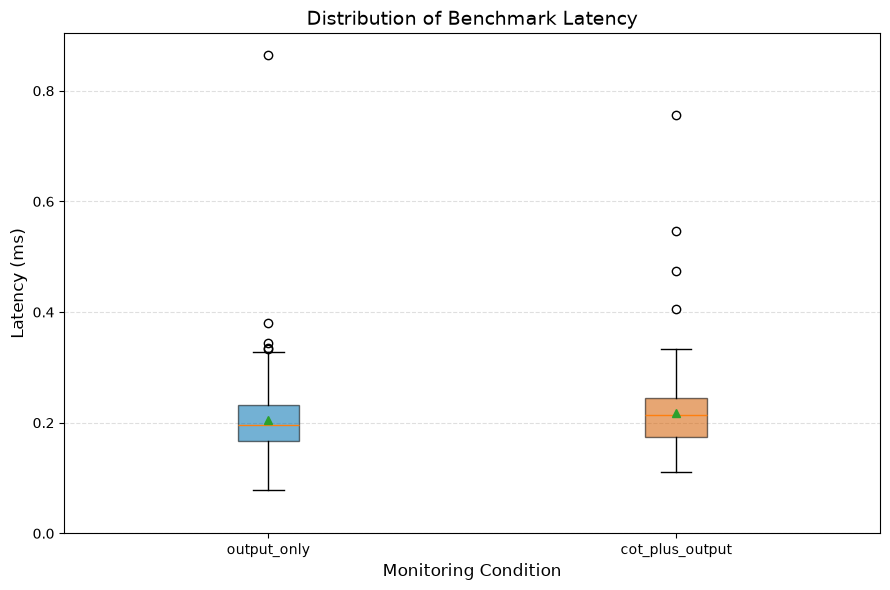

In [34]:
# Plot 2: Latency Distribution and Outliers

conditions = ["output_only", "cot_plus_output"]

values = [
    valid_latency_df[
        valid_latency_df["condition"] == condition
    ]["latency_ms"]
    for condition in conditions
]

fig, ax = plt.subplots(figsize=(9, 6))

boxplot = ax.boxplot(
    values,
    tick_labels=conditions,
    patch_artist=True,
    showmeans=True,
    showfliers=True
)

colors = ["#0072B2", "#D55E00"]

for patch, color in zip(boxplot["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.55)

ax.set_xlabel("Monitoring Condition", fontsize=12)
ax.set_ylabel("Latency (ms)", fontsize=12)
ax.set_title("Distribution of Benchmark Latency", fontsize=14)

ax.set_ylim(bottom=0)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "fig2_distribution_boxplot_notebook.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "fig2_distribution_boxplot_notebook.pdf",
    bbox_inches="tight"
)

plt.show()

## 10. Results and Interpretation

The analysis compares the latency of the output_only and cot_plus_output monitoring conditions.

The results are interpreted using descriptive statistics, bootstrap confidence intervals, and latency distributions.

Potential outliers are retained in the analysis.

The current experiment uses a keyword-based monitoring backend and a small demonstration dataset. Therefore, the results represent preliminary technical measurements rather than conclusive evidence about real LLM monitoring performance.

In [24]:
for _, row in summary_df.iterrows():

    print(f"\nCondition: {row['condition']}")
    print(f"Mean latency: {row['mean']:.6f} ms")
    print(f"Median latency: {row['median']:.6f} ms")

    print(
        "95% Bootstrap CI: "
        f"[{row['bootstrap_ci_lower_ms']:.6f}, "
        f"{row['bootstrap_ci_upper_ms']:.6f}] ms"
    )

    print(f"Outliers: {row['outlier_count']}")


Condition: cot_plus_output
Mean latency: 0.041626 ms
Median latency: 0.039700 ms
95% Bootstrap CI: [0.039738, 0.043756] ms
Outliers: 5

Condition: output_only
Mean latency: 0.039856 ms
Median latency: 0.037200 ms
95% Bootstrap CI: [0.037666, 0.042274] ms
Outliers: 6


## 11. Conclusion

The notebook successfully loads, filters, analyzes, and visualizes benchmark latency measurements.

The analysis includes:
- Data validation and filtering
- Descriptive statistics
- 95% Bootstrap Confidence Intervals
- IQR-based outlier detection
- Statistical summary export
- Scientific visualizations

All analysis steps are reproducible using the provided dataset and configuration.



The benchmark experiment evaluated two monitoring conditions: `output_only` and `cot_plus_output` at four target request rates (1, 5, 10, and 20 RPS).

A total of 400 benchmark measurements were collected, excluding 20 warm-up measurements. No measurement errors were observed.

The analysis included mean latency, standard deviation, median, P95, P99, 95% bootstrap confidence intervals, achieved throughput, and non-destructive IQR outlier detection.

The visualizations show latency trends across different request rates and compare latency distributions between the two monitoring conditions.

The results describe the performance of the local keyword-based monitoring implementation under the tested conditions. They should not be interpreted as measurements of a production LLM API or as evidence of general performance differences.